1) Install libraries (run once)

In [1]:
!pip -q install shap lime dice-ml captum gradio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 19.6 MB/s eta 0:00:00


2. Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    precision_score, recall_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from matplotlib.colors import ListedColormap

import shap
from lime.lime_tabular import LimeTabularExplainer

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from captum.attr import IntegratedGradients

import dice_ml
from dice_ml import Dice

3) Load data + rename columns + encode target

In [3]:
DATA_PATH = "/content/drive/MyDrive/coding/Heart disease.csv"
data_raw = pd.read_csv(DATA_PATH)

print("Raw shape:", data_raw.shape)
print(data_raw.head())
print(list(data_raw.columns))

Raw shape: (70000, 11)
   Gender (0: female, 1: male)  age(years)        BMI  \
0                            1          50  21.967120   
1                            0          55  34.927679   
2                            0          52  23.507805   
3                            1          48  28.710479   
4                            0          48  23.011177   

   ap_hi(Systolic blood pressure)  ap_lo(Diastolic blood pressure)  \
0                             110                               80   
1                             140                               90   
2                             130                               70   
3                             150                              100   
4                             100                               60   

   cholesterol(1: normal, 2: above normal, 3: well above normal)  \
0                                                  1               
1                                                  3               
2        

In [4]:
data = data_raw.rename(columns={
    'Gender (0: female, 1: male)' : 'Gender',
    'age(years)'                  : 'Age',
    'BMI'                         : 'BMI',
    'ap_hi(Systolic blood pressure)'  : 'SBP',
    'ap_lo(Diastolic blood pressure)' : 'DBP',
    'cholesterol(1: normal, 2: above normal, 3: well above normal)' : 'Cholesterol',
    'Glucose(1: normal, 2: above normal, 3: well above normal)'     : 'Glucose',
    'cardiovascular disease'      : 'CVD_text'
})

# If your file already has 0/1 target, replace this encoding accordingly.
data['CVD'] = (data['CVD_text'].astype(str).str.lower().str.contains("has")).astype(int)

print(data[['CVD_text','CVD']].head())
print("Target distribution:\n", data['CVD'].value_counts())

                               CVD_text  CVD
0  does not have cardiovascular disease    0
1            has cardiovascular disease    1
2            has cardiovascular disease    1
3            has cardiovascular disease    1
4  does not have cardiovascular disease    0
Target distribution:
 CVD
0    35021
1    34979
Name: count, dtype: int64


# 4. Basic data check and recommended cleaning

4.1 Check ranges

In [5]:
print(data[['Age','BMI','SBP','DBP']].describe())

                Age           BMI           SBP           DBP
count  70000.000000  70000.000000  70000.000000  70000.000000
mean      53.338686     27.556513    128.817286     96.630414
std        6.765294      6.091511    154.011419    188.472530
min       30.000000      3.471784   -150.000000    -70.000000
25%       48.000000     23.875115    120.000000     80.000000
50%       54.000000     26.374068    120.000000     80.000000
75%       58.000000     30.222222    140.000000     90.000000
max       65.000000    298.666667  16020.000000  11000.000000


4.2 Clean outliers

In [6]:
df = data.copy()

# Drop missing values for core columns
needed = ['Gender','Age','BMI','SBP','DBP','Cholesterol','Glucose','smoking','alcohol','active','CVD']
df = df.dropna(subset=needed)

# Plausible ranges
df = df[
    (df['BMI'] >= 12) & (df['BMI'] <= 60) &
    (df['SBP'] >= 80) & (df['SBP'] <= 260) &
    (df['DBP'] >= 40) & (df['DBP'] <= 140)
]

# SBP must be greater than DBP
df = df[df['SBP'] > df['DBP']]

print("After cleaning, shape:", df.shape)
print(df['CVD'].value_counts())

After cleaning, shape: (68592, 12)
CVD
0    34659
1    33933
Name: count, dtype: int64


5. Feature engineering (Pulse Pressure, MAP, risk count)

In [7]:
df['PP']  = df['SBP'] - df['DBP']                 # pulse pressure
df['MAP'] = (df['SBP'] + 2*df['DBP']) / 3.0       # mean arterial pressure

df['risk_count'] = (
    (df['Cholesterol'] > 1).astype(int) +
    (df['Glucose'] > 1).astype(int) +
    df['smoking'].astype(int) +
    df['alcohol'].astype(int) +
    (1 - df['active'].astype(int))
)

print(df[['PP','MAP','risk_count']].describe())

                 PP           MAP    risk_count
count  68592.000000  68592.000000  68592.000000
mean      45.367740     96.422455      0.737841
std       11.659327     11.018797      0.878848
min        5.000000     53.333333      0.000000
25%       40.000000     93.333333      0.000000
50%       40.000000     93.333333      1.000000
75%       50.000000    103.333333      1.000000
max      140.000000    173.333333      5.000000


6. Final features (10 base + 3 engineered = 13)


In [8]:
base_features = [
    "Gender","Age","BMI","SBP","DBP",
    "Cholesterol","Glucose","smoking","alcohol","active"
]
engineered_features = ["PP","MAP","risk_count"]

feature_cols = base_features + engineered_features
target_col = "CVD"

X = df[feature_cols].copy()
y = df[target_col].astype(int).copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class labels:", np.unique(y))

X shape: (68592, 13)
y shape: (68592,)
Class labels: [0 1]


7. Correlation heatmap (EDA)

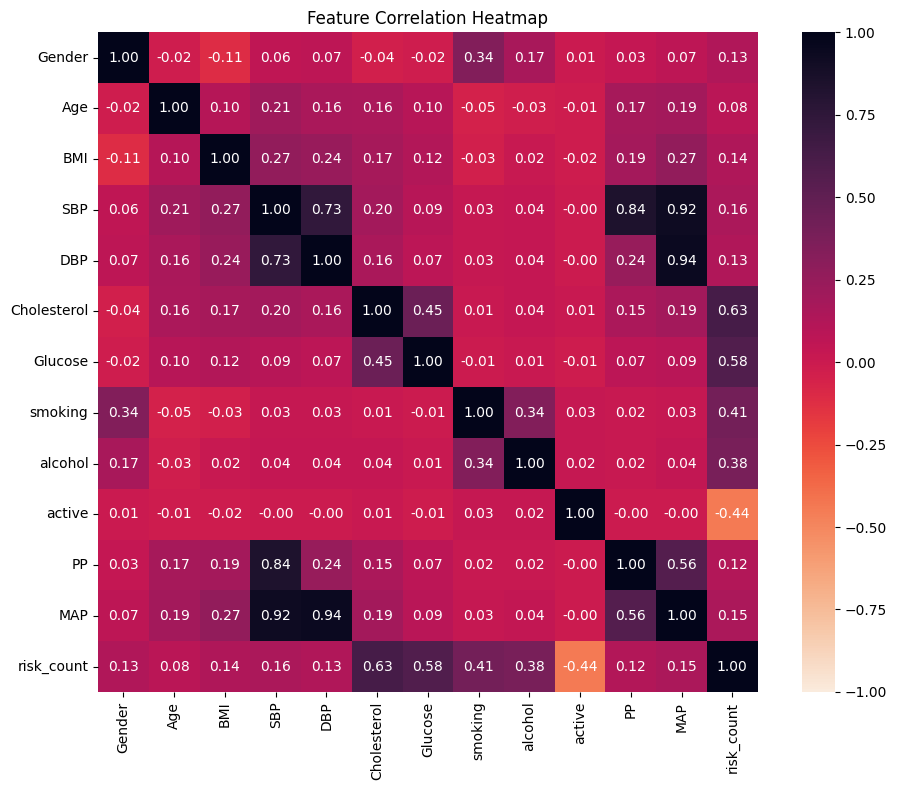

In [9]:
corr = X.corr()

rocket_cmap = sns.color_palette("rocket", as_cmap=True).reversed()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap=rocket_cmap,
    vmin=-1, vmax=1,
    square=True
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

8. Train / validation / test split (70% / 15% / 15%)

In [10]:
# First: 15% test, 85% temp
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    stratify=y,
    random_state=42
)

# Then: from the remaining 85%, split into 70% train and 15% validation
# 0.15 / 0.85 ≈ 0.1765
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1765,
    stratify=y_temp,
    random_state=42
)

print("Train:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)

Train: (48012, 13)
Val  : (10291, 13)
Test : (10289, 13)


# 8) Baseline models (DT, NB, kNN, LR, RF, SVM, MLP) + comparison table

8.1 Helper function to evaluate any model

In [11]:
def eval_on_val_and_test(name, fitted_model,
                         X_val, y_val,
                         X_test, y_test):
    """Return a dict of metrics for a fitted classifier."""
    y_val_proba  = fitted_model.predict_proba(X_val)[:, 1]
    y_val_pred   = fitted_model.predict(X_val)

    y_test_proba = fitted_model.predict_proba(X_test)[:, 1]
    y_test_pred  = fitted_model.predict(X_test)

    return {
        "Model": name,
        "Val AUC":  roc_auc_score(y_val,  y_val_proba),
        "Val acc":  accuracy_score(y_val,  y_val_pred),
        "Val F1":   f1_score(y_val,  y_val_pred),
        "Test AUC": roc_auc_score(y_test, y_test_proba),
        "Test acc": accuracy_score(y_test, y_test_pred),
        "Test F1":  f1_score(y_test, y_test_pred),
    }

Hyperparameter tuning using optuna

In [12]:
models = {}

# DT
models["Decision Tree (DT)"] = DecisionTreeClassifier(random_state=42)

# NB
models["Naive Bayes (NB)"] = GaussianNB()

# kNN
models["k-NN"] = Pipeline(
    [("scaler", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=15))]
)

# LR
models["Logistic Regression (LR)"] = Pipeline(
    [("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]
)

# RF
models["Random Forest (RF)"] = RandomForestClassifier(
    n_estimators=400, random_state=42, n_jobs=-1
)

# SVM (RBF)
models["SVM (RBF)"] = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", probability=True, random_state=42)),
    ]
)

# MLP (sklearn)
models["MLP (sklearn)"] = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("clf", MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42)),
    ]
)

results = []
for name, m in models.items():
    m.fit(X_train, y_train)
    results.append(eval_on_val_and_test(name, m, X_val, y_val, X_test, y_test))

perf_df = pd.DataFrame(results).sort_values("Test AUC", ascending=False)
perf_df_rounded = perf_df.copy()
for c in perf_df.columns[1:]:
    perf_df_rounded[c] = perf_df_rounded[c].astype(float).round(3)

perf_df_rounded

,Model,Val AUC,Val acc,Val F1,Test AUC,Test acc,Test F1
6,MLP (sklearn),0.803,0.738,0.723,0.795,0.735,0.719
3,Logistic Regression (LR),0.798,0.732,0.712,0.790,0.728,0.706
5,SVM (RBF),0.794,0.737,0.712,0.784,0.733,0.707
1,Naive Bayes (NB),0.791,0.725,0.686,0.779,0.719,0.682
2,k-NN,0.787,0.724,0.710,0.775,0.720,0.705
4,Random Forest (RF),0.747,0.688,0.684,0.738,0.681,0.676
0,Decision Tree (DT),0.643,0.642,0.628,0.634,0.633,0.620


9) Choose the main model for explainability

In [13]:
proposed = models["MLP (sklearn)"]
proposed_name = "MLP (Proposed)"

Make a comparison table (for the paper)

In [14]:
# The 'perf_df_rounded' DataFrame is already computed in the previous cell (269YnDIscL01)
# and contains the evaluation metrics for all baseline models, including the MLP (sklearn).
# So, we can directly print it here.

print(perf_df_rounded)
# The line `df.round(3)` was a leftover and is not needed.

                      Model  Val AUC  Val acc  Val F1  Test AUC  Test acc  \
6             MLP (sklearn)    0.803    0.738   0.723     0.795     0.735   
3  Logistic Regression (LR)    0.798    0.732   0.712     0.790     0.728   
5                 SVM (RBF)    0.794    0.737   0.712     0.784     0.733   
1          Naive Bayes (NB)    0.791    0.725   0.686     0.779     0.719   
2                      k-NN    0.787    0.724   0.710     0.775     0.720   
4        Random Forest (RF)    0.747    0.688   0.684     0.738     0.681   
0        Decision Tree (DT)    0.643    0.642   0.628     0.634     0.633   

   Test F1  
6    0.719  
3    0.706  
5    0.707  
1    0.682  
2    0.705  
4    0.676  
0    0.620  


# 10. Final evaluation on test set

Confusion matrices (train + test)

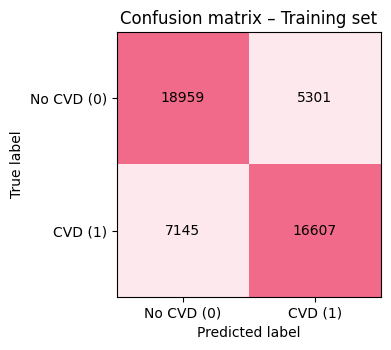

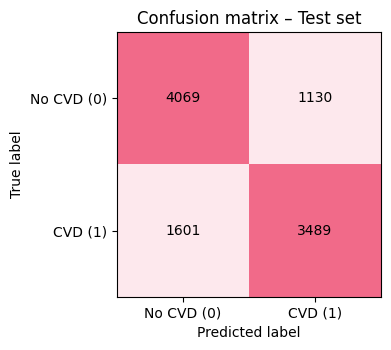

In [15]:
from matplotlib.colors import ListedColormap

# Custom 2-colour colormap for CM, if you like
cm_colors = ListedColormap(["#FDE8ED", "#F16A89"])

# Calculate predictions for the proposed model
y_train_pred = proposed.predict(X_train)
y_test_proba = proposed.predict_proba(X_test)[:, 1]
y_test_pred  = proposed.predict(X_test)

# TRAIN CM
cm_train = confusion_matrix(y_train, y_train_pred)
disp_train = ConfusionMatrixDisplay(cm_train, display_labels=["No CVD (0)", "CVD (1)"])

fig, ax = plt.subplots(figsize=(4, 4))
disp_train.plot(cmap=cm_colors, values_format="d", colorbar=False, ax=ax)
for text in disp_train.text_.ravel():
    text.set_color("black")
ax.set_title("Confusion matrix – Training set")
plt.tight_layout()
plt.show()

# TEST CM
cm_test = confusion_matrix(y_test, y_test_pred)
disp_test = ConfusionMatrixDisplay(cm_test, display_labels=["No CVD (0)", "CVD (1)"])

fig, ax = plt.subplots(figsize=(4, 4))
disp_test.plot(cmap=cm_colors, values_format="d", colorbar=False, ax=ax)
for text in disp_test.text_.ravel():
    text.set_color("black")
ax.set_title("Confusion matrix – Test set")
plt.tight_layout()
plt.show()

In [16]:
test_acc = accuracy_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_proba)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test ROC-AUC : {test_auc:.3f}")

print("\nClassification report (test):")
print(classification_report(y_test, y_test_pred, digits=3))

Test accuracy: 0.735
Test ROC-AUC : 0.795

Classification report (test):
              precision    recall  f1-score   support

           0      0.718     0.783     0.749      5199
           1      0.755     0.685     0.719      5090

    accuracy                          0.735     10289
   macro avg      0.736     0.734     0.734     10289
weighted avg      0.736     0.735     0.734     10289



ROC curves

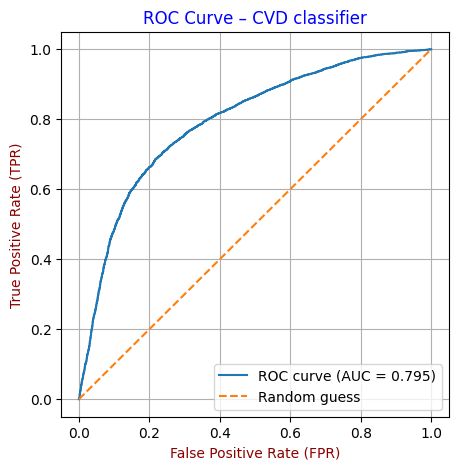

In [19]:
# ROC
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guess")
font1 = {'family':' times new Roman','color':'blue','size':12}
font2 = {'family':' times new Roman','color':'darkred','size':10}
plt.xlabel("False Positive Rate (FPR)",fontdict=font2)
plt.ylabel("True Positive Rate (TPR)",fontdict=font2)
plt.title("ROC Curve – CVD classifier",fontdict=font1)
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Precision–Recall curve

In [ ]:
precision, recall, _ = precision_recall_curve(y_test, y_test_proba)
ap = average_precision_score(y_test, y_test_proba)

plt.figure(figsize=(5, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall Curve (AP = {ap:.3f})")
plt.grid(True)
plt.show()

11. Global explainability (Permutation importance + PDP)

In [ ]:
# Permutation importance
result_perm = permutation_importance(
    proposed,
    X_test,
    y_test,
    n_repeats=10,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42
)

perm_importance = pd.Series(
    result_perm.importances_mean,
    index=feature_cols
).sort_values(ascending=False)

print(perm_importance)

plt.figure(figsize=(6, 4))
perm_importance.plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Permutation importance (mean AUC drop)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

Partial dependence plots for key features

In [ ]:
features_to_plot = ["Age", "BMI", "SBP"]

fig, ax = plt.subplots(figsize=(8, 6))
PartialDependenceDisplay.from_estimator(
    proposed,
    X_train,
    features_to_plot,
    kind="average",
    ax=ax
)
plt.tight_layout()
plt.show()

# A) Transfer Learning (Pretrain → Fine-tune) with PyTorch

11) Prepare scaled tensors

In [ ]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_sc, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32)

X_val_t   = torch.tensor(X_val_sc, dtype=torch.float32)
y_val_t   = torch.tensor(y_val.values, dtype=torch.float32)

X_test_t  = torch.tensor(X_test_sc, dtype=torch.float32)
y_test_t  = torch.tensor(y_test.values, dtype=torch.float32)

n_features = X_train_t.shape[1]
print("n_features:", n_features)

12) Define models: Autoencoder (pretrain) + Classifier (fine-tune)

In [ ]:
class Encoder(nn.Module):
    def __init__(self, d_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )
    def forward(self, x):
        return self.net(x)

class AutoEncoder(nn.Module):
    def __init__(self, d_in):
        super().__init__()
        self.encoder = Encoder(d_in)
        self.decoder = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, d_in)
        )
    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat

class Classifier(nn.Module):
    def __init__(self, d_in, encoder=None):
        super().__init__()
        self.encoder = encoder if encoder is not None else Encoder(d_in)
        self.head = nn.Sequential(
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)  # logits
        )
    def forward(self, x):
        z = self.encoder(x)
        logits = self.head(z).squeeze(1)
        return logits

13) Pretrain autoencoder (self-supervised transfer)

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
ae = AutoEncoder(n_features).to(device)

opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

X_tr = X_train_t.to(device)

ae.train()
for epoch in range(30):
    opt.zero_grad()
    x_hat = ae(X_tr)
    loss = loss_fn(x_hat, X_tr)
    loss.backward()
    opt.step()
    if (epoch+1) % 10 == 0:
        print(f"AE epoch {epoch+1:02d} | recon loss = {loss.item():.4f}")

14) Fine-tune classifier using pretrained encoder

In [ ]:
clf = Classifier(n_features, encoder=ae.encoder).to(device)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
bce = nn.BCEWithLogitsLoss()

def eval_torch(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X.to(device))
        proba  = torch.sigmoid(logits).cpu().numpy()
        pred   = (proba >= 0.5).astype(int)
    y_np = y.cpu().numpy().astype(int)
    return (
        roc_auc_score(y_np, proba),
        accuracy_score(y_np, pred),
        f1_score(y_np, pred)
    )

clf.train()
for epoch in range(30):
    opt.zero_grad()
    logits = clf(X_train_t.to(device))
    loss = bce(logits, y_train_t.to(device))
    loss.backward()
    opt.step()

    if (epoch+1) % 10 == 0:
        val_auc, val_acc, val_f1 = eval_torch(clf, X_val_t, y_val_t)
        print(f"CLF epoch {epoch+1:02d} | loss={loss.item():.4f} | val_auc={val_auc:.3f} val_acc={val_acc:.3f} val_f1={val_f1:.3f}")

15) Test performance (Transfer model)

In [ ]:
test_auc_t, test_acc_t, test_f1_t = eval_torch(clf, X_test_t, y_test_t)
print("Transfer-learning (AE→MLP) TEST:",
      f"AUC={test_auc_t:.3f}, Acc={test_acc_t:.3f}, F1={test_f1_t:.3f}")

# B) Federated Learning (FedAvg) simulation with PyTorch

16) Create “clients” from training set

In [ ]:
def split_clients(X, y, n_clients=5):
    idx = np.arange(len(X))
    np.random.RandomState(42).shuffle(idx)
    splits = np.array_split(idx, n_clients)
    clients = []
    for s in splits:
        clients.append((X[s], y[s]))
    return clients

clients = split_clients(X_train_t, y_train_t, n_clients=5)
print("Clients:", [len(c[0]) for c in clients])

17) FedAvg training loop

In [ ]:
def get_model():
    # fresh model for FL (same architecture as classifier)
    return Classifier(n_features).to(device)

def local_train(model, Xc, yc, epochs=2, lr=1e-3):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    Xc = Xc.to(device)
    yc = yc.to(device)
    for _ in range(epochs):
        opt.zero_grad()
        logits = model(Xc)
        loss = loss_fn(logits, yc)
        loss.backward()
        opt.step()
    return model.state_dict()

def fedavg(state_dicts):
    # average weights
    avg = {}
    for k in state_dicts[0].keys():
        avg[k] = sum(sd[k] for sd in state_dicts) / len(state_dicts)
    return avg

global_model = get_model()

rounds = 20
for r in range(rounds):
    local_states = []
    for (Xc, yc) in clients:
        # start from global weights
        local_model = get_model()
        local_model.load_state_dict(global_model.state_dict())

        sd = local_train(local_model, Xc, yc, epochs=2, lr=1e-3)
        local_states.append(sd)

    global_sd = fedavg(local_states)
    global_model.load_state_dict(global_sd)

    if (r+1) % 5 == 0:
        val_auc, val_acc, val_f1 = eval_torch(global_model, X_val_t, y_val_t)
        print(f"Round {r+1:02d} | val_auc={val_auc:.3f}, val_acc={val_acc:.3f}, val_f1={val_f1:.3f}")

18) Federated test performance

In [ ]:
test_auc_fl, test_acc_fl, test_f1_fl = eval_torch(global_model, X_test_t, y_test_t)
print("Federated (FedAvg) TEST:",
      f"AUC={test_auc_fl:.3f}, Acc={test_acc_fl:.3f}, F1={test_f1_fl:.3f}")

19) Integrated Gradients (PyTorch model) – global + single patient

Single patient IG

In [ ]:
ig = IntegratedGradients(global_model)

idx = 14
x0 = X_test_t[idx:idx+1].to(device)

global_model.eval()
attr = ig.attribute(x0, target=None)  # binary logit
attr = attr.detach().cpu().numpy().reshape(-1)

ig_single = pd.Series(attr, index=feature_cols).sort_values(key=np.abs, ascending=False)
print(ig_single.head(10))

In [ ]:
plt.figure(figsize=(6,4))
ig_single.head(10)[::-1].plot(kind="barh")
plt.title("Integrated Gradients (single patient) – top features")
plt.tight_layout()
plt.show()

Global IG (mean |IG| over test set)

In [ ]:
all_attr = []
for i in range(len(X_test_t)):
    a = ig.attribute(X_test_t[i:i+1].to(device))
    all_attr.append(a.detach().cpu().numpy().reshape(-1))

all_attr = np.vstack(all_attr)
mean_abs_ig = np.mean(np.abs(all_attr), axis=0)

ig_global = pd.Series(mean_abs_ig, index=feature_cols).sort_values(ascending=False)
print(ig_global)

In [ ]:
plt.figure(figsize=(6,4))
ig_global[::-1].plot(kind="barh")
plt.title("Integrated Gradients global importance (mean |IG|)")
plt.tight_layout()
plt.show()

20) DiCE counterfactuals (fully working) — using your “proposed” sklearn model

In [ ]:
# Prepare Dice data object
dice_df = df[feature_cols + [target_col]].copy()

d = dice_ml.Data(
    dataframe=dice_df,
    continuous_features=["Age","BMI","SBP","DBP","PP","MAP","risk_count"],
    outcome_name=target_col
)

m = dice_ml.Model(model=proposed, backend="sklearn")

dice = Dice(d, m, method="random")   # stable in Colab

In [ ]:
# Pick an instance (from test set)
query_instance = X_test.iloc[[0]].copy()
print("Query instance:\n", query_instance)

dice_exp = dice.generate_counterfactuals(
    query_instance,
    total_CFs=3,
    desired_class=0,   # want "No CVD"
    features_to_vary=["SBP","DBP","Cholesterol","Glucose","smoking","alcohol","active","BMI"]
)

dice_exp.visualize_as_dataframe()

## 12. SHAP setup (global & local)

In [ ]:
shap.initjs()

# background data for SHAP (from train set)
X_background = X_train.sample(300, random_state=42)

# Explainer for predict_proba
explainer = shap.Explainer(proposed.predict_proba, X_background)
class_idx = 1  # CVD = 1

# Compute SHAP on test data
X_explain = X_test.copy()
shap_values_all = explainer(X_explain)        # shape: (n_samples, 2, n_features)
shap_values_cvd = shap_values_all[..., 1]     # class 1 only

print("shap_values_cvd shape:", shap_values_cvd.values.shape)

# SHAP global plots

Bar plot of mean |SHAP|

In [ ]:
shap.plots.bar(shap_values_cvd, max_display=len(feature_cols))

Beeswarm plot

In [ ]:
shap.plots.beeswarm(shap_values_cvd)

Dependence plot: BMI

In [ ]:
shap.plots.scatter(shap_values_cvd[:, "BMI"])               # SHAP vs BMI

Dependence plot: BMI(culoured)

In [ ]:
shap.plots.scatter(shap_values_cvd[:, "BMI"],
                   color=shap_values_cvd[:, "Age"])         # coloured by Age

13. SHAP local plots (one example patient)

In [ ]:
# choose an index from the test set
#idx = 14

print("Example test patient features:")
print(X_test.iloc[idx])

shap.plots.waterfall(shap_values_cvd[idx], max_display=10)

Force plot (static)

In [ ]:
shap.plots.force(shap_values_cvd[idx], matplotlib=True)

14. LIME local explanation (same patient index)

In [ ]:
# Prepare NumPy arrays
X_train_np = X_train.values
X_test_np  = X_test.values

class_names = ["No CVD (0)", "CVD (1)"]

lime_explainer = LimeTabularExplainer(
    training_data = X_train_np,
    feature_names = feature_cols,
    class_names   = class_names,
    mode          = "classification",
    discretize_continuous = True
)

# Explain the same test instance as SHAP (idx)
x_instance = X_test_np[idx]

lime_exp = lime_explainer.explain_instance(
    data_row   = x_instance,
    predict_fn = proposed.predict_proba,
    num_features = 10,
    top_labels   = 2
)

fig = lime_exp.as_pyplot_figure(label=1)
plt.title("LIME local explanation for one test patient (class = CVD)")
plt.tight_layout()
plt.show()

# LIME table
lime_list = lime_exp.as_list(label=1)
lime_df = pd.DataFrame(lime_list, columns=["Feature (condition)", "LIME weight"])

patient_series = X_test.iloc[idx]
patient_dict   = patient_series.to_dict()

def extract_feature_name(lime_cond):
    return lime_cond.split()[0]

lime_df["Feature"] = lime_df["Feature (condition)"].apply(extract_feature_name)
lime_df["Patient value"] = lime_df["Feature"].map(patient_dict)

lime_df = lime_df[["Feature", "Patient value", "Feature (condition)", "LIME weight"]]
print(lime_df)

Clustering (K-Means)

In [ ]:
from sklearn.cluster import KMeans

# Select relevant features for clustering
X_clust = X[['Age', 'BMI', 'SBP', 'DBP']]

# Apply KMeans clustering
kmeans = KMeans(n_clusters=3, random_state=42)
X_clust['cluster'] = kmeans.fit_predict(X_clust)

# Visualize clusters
import seaborn as sns
sns.scatterplot(x=X_clust['Age'], y=X_clust['BMI'], hue=X_clust['cluster'], palette='viridis')
plt.title("Clustering patients based on Age and BMI")
plt.show()


Simple “what-if” / counterfactual curve

In [ ]:
def what_if_curve(example_row, feature, value_grid):
    rows = []
    for v in value_grid:
        r = example_row.copy()
        r[feature] = v
        rows.append(r.iloc[0])
    X_grid = pd.DataFrame(rows)
    proba_grid = proposed.predict_proba(X_grid)[:, 1]
    return value_grid, proba_grid

# Example: what-if curve for systolic BP (SBP)
# Use the same example patient from SHAP/LIME explanation
example_patient_row = X_test.iloc[[idx]] # Use double brackets to keep it a DataFrame

bp_grid = np.arange(100, 181, 10)  # 100, 110, ..., 180
vals, probs = what_if_curve(example_patient_row, "SBP", bp_grid)

plt.figure(figsize=(5, 4))
plt.plot(vals, probs, marker="o")
plt.xlabel("Systolic BP (SBP, mmHg)")
plt.ylabel("Predicted CVD probability")
plt.title("What-if curve for systolic BP (example patient)")
plt.grid(True)
plt.show()

Counterfactual Explanations

In [ ]:
import dice_ml
from dice_ml import Dice

# Combine X_train and y_train into a single DataFrame for DiCE
train_df_dice = X_train.copy()
train_df_dice['CVD'] = y_train

# Prepare DiCE model using RandomForest or Neural Network
dice_data = dice_ml.Data(dataframe=train_df_dice, continuous_features=feature_cols, outcome_name='CVD')

# Assuming 'rf_best' is your best Random Forest model from earlier cells
# If you want to use the MLP model, replace 'rf_best' with 'model'
model_dice = dice_ml.Model(model=proposed, backend="sklearn")

# Create DiCE explainer
dice_explainer = Dice(dice_data, model_dice)

# Generate counterfactual for a test patient
# We need to make sure the input to generate_counterfactuals also has all feature_cols
# X_test.iloc[0:1] correctly provides features for one sample
counterfactual = dice_explainer.generate_counterfactuals(X_test.iloc[0:1], total_CFs=3, desired_class="opposite")
counterfactual.visualize_as_dataframe(show_only_changes=True)

15. Fairness metrics by gender

In [ ]:
def group_metrics(group_value, group_name):
    mask = X_test["Gender"] == group_value

    y_true_g  = y_test[mask]
    y_pred_g  = y_test_pred[mask]
    y_proba_g = y_test_proba[mask]

    print(f"\n=== Metrics for {group_name} (Gender = {group_value}) ===")
    print("Samples in test set:", len(y_true_g))

    acc_g  = accuracy_score(y_true_g, y_pred_g)
    prec_g = precision_score(y_true_g, y_pred_g)
    rec_g  = recall_score(y_true_g, y_pred_g)

    tn, fp, fn, tp = confusion_matrix(y_true_g, y_pred_g).ravel()
    fpr_g = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    try:
        auc_g = roc_auc_score(y_true_g, y_proba_g)
    except ValueError:
        auc_g = float("nan")

    pos_rate = (y_pred_g == 1).mean()

    print(f"Accuracy      : {acc_g:.3f}")
    print(f"Precision     : {prec_g:.3f}")
    print(f"Recall (TPR)  : {rec_g:.3f}")
    print(f"False Pos Rate: {fpr_g:.3f}")
    print(f"Positive rate : {pos_rate:.3f}")
    print(f"AUC           : {auc_g:.3f}")

group_metrics(0, "Female")
group_metrics(1, "Male")